# Run programs through QDMI

The compiler decides how a program fits a device. QDMI provides the next part of
the workflow: discover that device, submit a job, wait for completion, and read
its results. How do individual shots relate to a histogram? When can a simulator
also return a statevector? Can you reuse a compiled program?

This notebook answers those questions with local DDSIM. It runs independently
with the [tutorial setup](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/index.html#run-the-notebooks), without credentials or an
external device. The [QDMI guide](https://mqt.readthedocs.io/projects/core/en/stable/qdmi/index.html) explains the driver,
client interfaces, device implementations, and SDK integrations.

:::{admonition} Your turn
:class: tip

**Notebook 03 · 30 minutes.** Discover DDSIM and inspect its capabilities
(5 min), compile and submit a program (10 min), then compare counts with shots
and reuse the compiled program (10 min). Use the last 5 minutes to change the
shot count and explain what does and does not need recompilation.
:::

Statevector
extraction and format selection are optional extensions.

In [1]:
from collections import Counter
from math import cos, pi, sin

import numpy as np
from qiskit.visualization import plot_distribution

from mqt.core.mlir import compile_program, submit_program
from mqt.core.qdmi import ProgramFormat, device_ids, open_device

## Discover a device and inspect its capabilities

Device IDs identify configured device definitions. Listing them does not submit
a program. The bundled simulator has the stable ID `mqt.ddsim.default`:

In [2]:
print("Registered devices:", device_ids())
device = open_device("mqt.ddsim.default")
print("Device:", device.name())
print("Status:", device.status().name)
formats = device.supported_program_formats()
print("Accepted formats:", [program_format.name for program_format in formats])

Registered devices: ['mqt.ddsim.default', 'mqt.sc.default', 'mqt.sc.ibm.heron', 'mqt.sc.ibm.nighthawk', 'mqt.sc.iqm.emerald', 'mqt.sc.iqm.garnet']
Device: MQT Core DDSIM QDMI Device
Status: IDLE
Accepted formats: ['QASM2', 'QASM3', 'QIR_BASE_STRING', 'QIR_BASE_MODULE', 'QIR_ADAPTIVE_STRING', 'QIR_ADAPTIVE_MODULE']


The accepted formats tell the client how to encode a program. Device queries
also expose available operations, sites, and calibration properties. The target
compiler uses that information; callers do not need to reproduce its gate
mapping logic.

Opening another registered device may initialize access to a provider. Keep
DDSIM selected here; use the [configuration guide](https://mqt.readthedocs.io/projects/core/en/stable/qdmi/configuration.html)
when connecting an external library or service.

## Compile a program with a predictable distribution

Choose an angle $\theta$. Applying $R_y(\theta)$ to qubit 0 and a controlled-X
to qubit 1 produces $\cos(\theta/2)|00\rangle + \sin(\theta/2)|11\rangle$.

:::{admonition} Your turn
:class: tip

For
$\theta=\pi/3$, predict the probabilities of `00` and `11`.
:::

In [3]:
theta = pi / 3
shots = 2048
seed = 17
source = f"""OPENQASM 3.0;
include "stdgates.inc";
qubit[2] q;
ry({theta}) q[0];
cx q[0], q[1];
bit[2] result = measure q;
"""

compiled = compile_program(source, target=device)
print("Selected format:", compiled.program_format.name)
print("Payload size:", len(compiled.payload))

Selected format: QASM3
Payload size: 124


The returned `CompiledProgram` stores the serialized program and the target
requirements used to produce it. The compiler selects a native format from those
supported by the device. Reusing this object avoids recompilation for subsequent
jobs.

## Submit, wait, and retrieve counts

Compilation does not submit a job. Name the destination explicitly when calling
`submit_program`:

In [4]:
job = submit_program(compiled, target=device, num_shots=shots, custom1=seed)
assert job.wait()
print("Final job status:", job.check().name)
counts = job.get_counts()
assert sum(counts.values()) == shots
assert set(counts) == {"00", "11"}
print(counts)

Final job status: DONE
{'00': 1556, '11': 492}


`job.wait()` waits for completion and reports a failed execution. A finite
`timeout` lets a client stop waiting without cancelling the job. DDSIM uses
`custom1` as a positive integer random seed; custom parameters are defined by
each device, not by the generic QDMI interface.

:::{admonition} Your turn
:class: tip

Compare the sampled distribution with the analytic prediction:
:::

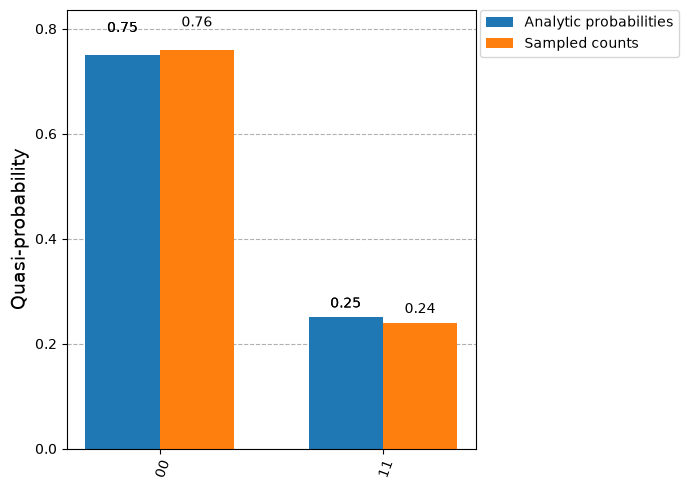

In [5]:
expected = {"00": cos(theta / 2) ** 2, "11": sin(theta / 2) ** 2}
assert abs(counts["00"] / shots - expected["00"]) < 0.05
plot_distribution([expected, counts], legend=["Analytic probabilities", "Sampled counts"])

:::{dropdown} Explain the result

The probabilities are $3/4$ for `00` and $1/4$ for `11`. Finite-shot counts
fluctuate around those values. Increasing the shot count reduces sampling noise;
it does not change the underlying state.
:::

## Recover individual shots

A histogram records how often each outcome occurs. `get_shots()` returns each
individual outcome in unspecified order, and counting them must reconstruct the
same histogram:

In [6]:
samples = job.get_shots()
assert len(samples) == shots
assert dict(Counter(samples)) == counts
assert job.get_counts() == counts
print("First 16 shots:", samples[:16])

First 16 shots: ['00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00', '00']


Reading results again does not rerun the program. QDMI bitstrings put the
highest-index output bit first. The [QIR tutorial](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/qir_execution.html) uses
asymmetric outputs to make that ordering visible.

## Reuse the compiled program

The number of shots is a job parameter.

:::{admonition} Your turn
:class: tip

Submit the same compiled artifact again
with a smaller shot count; no recompilation is needed while the target
requirements still match:
:::

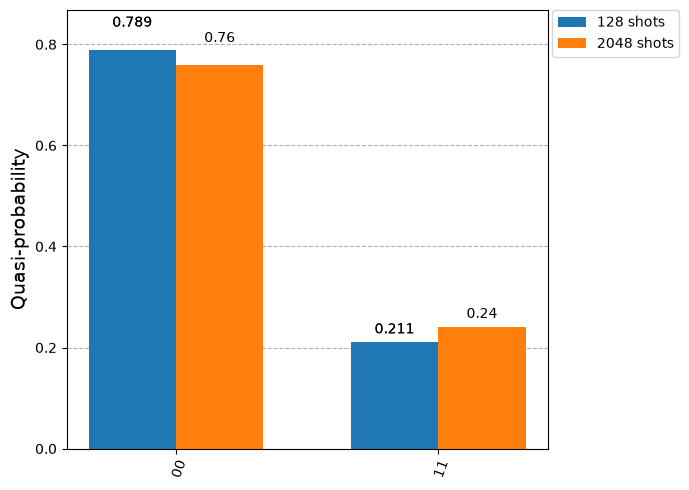

In [7]:
small_job = submit_program(compiled, target=device, num_shots=128, custom1=seed)
assert small_job.wait()
assert sum(small_job.get_counts().values()) == 128
assert job.get_counts() == counts
plot_distribution([small_job.get_counts(), counts], legend=["128 shots", "2048 shots"])

:::{admonition} Your turn
:class: tip

**Experiment:** change `theta` to `pi / 2`, rerun from the source cell, and
predict the new probabilities.
:::

Changing the circuit requires recompilation;
changing only the shot count requires another submission.

## Checkpoint: the device/job workflow is complete

You have discovered a device, compiled a program, submitted a job, read its
results, and reused the compiled artifact.

:::{admonition} Your turn
:class: tip

Return to the slides for questions.
:::

The remaining sections are optional extensions.

## Optional: inspect the simulator state

DDSIM can also return this program's statevector and probabilities. State
extraction depends on the execution path.

:::{admonition} Your turn
:class: tip

Request OpenQASM with zero shots to
inspect the state without sampling:
:::

In [8]:
state_job = submit_program(source, target=device, program_format=ProgramFormat.QASM3, num_shots=0)
assert state_job.wait()
state = state_job.get_dense_statevector()
probabilities = state_job.get_dense_probabilities()
expected_state = np.array([cos(theta / 2), 0, 0, sin(theta / 2)], dtype=complex)
np.testing.assert_allclose(state, expected_state, rtol=0, atol=1e-12)
np.testing.assert_allclose(probabilities, np.abs(expected_state) ** 2, rtol=0, atol=1e-12)
print("Statevector:", state)
print("Probabilities:", probabilities)

Statevector: [0.8660254+0.j 0.       +0.j 0.       +0.j 0.5      +0.j]
Probabilities: [0.75 0.   0.   0.25]


These are simulator results, not measurements available from physical hardware.
They describe the state before terminal measurement, not one randomly collapsed
shot. Jobs with feedback, resets, or other ineligible execution paths do not
provide this state. The [DDSIM guide](https://mqt.readthedocs.io/projects/core/en/stable/qdmi/ddsim_device.html) specifies
which sampling and zero-shot extraction jobs support it.

## Optional: change the program format

To select an exact execution format, pass `program_format` to `submit_program`.
Here we explicitly select QIR Base to compare with the default format reported above. This compiles and submits the source in one call:

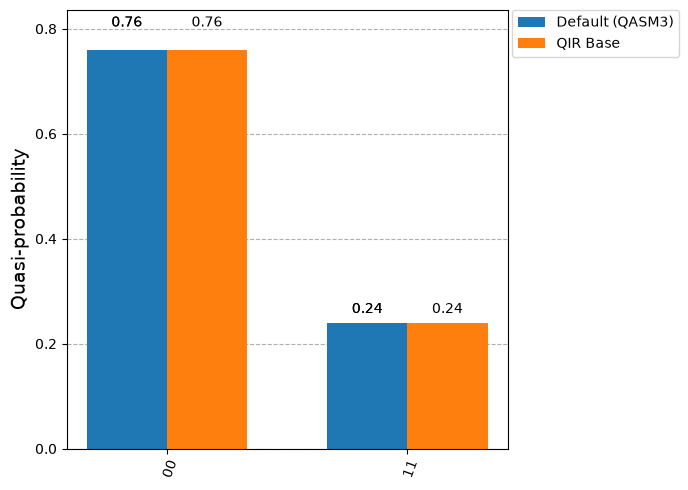

In [9]:
qir_job = submit_program(
    source, target=device, program_format=ProgramFormat.QIR_BASE_MODULE, num_shots=shots, custom1=seed
)
assert qir_job.wait()
qir_counts = qir_job.get_counts()
assert sum(qir_counts.values()) == shots
assert abs(qir_counts.get("00", 0) / shots - expected["00"]) < 0.05
plot_distribution([counts, qir_counts], legend=[f"Default ({compiled.program_format.name})", "QIR Base"])

The execution format changed, but the QDMI job workflow stayed the same.
Different execution paths can use different random sequences; compare the
semantics and distribution rather than requiring identical counts.

Use [Qiskit](https://mqt.readthedocs.io/projects/core/en/stable/qdmi/qdmi_backend.html) or
[PennyLane](https://mqt.readthedocs.io/projects/core/en/stable/qdmi/pennylane_device.html) to access QDMI through an SDK, and
the
[MQSC Orchestrator](https://github.com/munich-quantum-software/orchestrator)
to coordinate hybrid workflows with Slurm. A compiled artifact must still match
the selected device's capabilities; a stable ID does not make artifacts portable
to an unrelated target.

Continue with [Exchange structured programs with jeff](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/jeff_exchange.html) to exchange a structured program before
choosing its final execution format or device.